# 08 · Fase D — Grad-CAM de R0–R3: ¿los SBI llevan la atención al borde de la mezcla?
Es el diagnóstico del notebook 06 aplicado a los modelos de la Fase D (notebook 07, semilla 42). El 06 queda como está: sus salidas respaldan C-01.

**Predicción 4 de H-D1 (escrita antes de correr el 07, D-14):** con el Grad-CAM del notebook 06 sobre el checkpoint **R1**, la masa en el anillo del **borde** de la cara sube en los falsos frente a R0. Los SBI solo tienen el artefacto de mezcla, así que el modelo debería aprender a mirarlo.

*Qué la refutaría:* que la masa de borde en los falsos de R1 sea igual o menor que en R0 (IC 95 % del Δ que incluya 0 o sea negativo). En ese caso la mejora en FaceSwap y Face2Face se explicaría por otra señal (por ejemplo, del interior o de frecuencia) y habría que decirlo.

**Complementos (descriptivos, no son predicciones):** lo mismo con R2 y R3; y en FaceSwap, dónde mira R3 en los videos que ahora detecta frente a los que sigue sin detectar.

**Método:** igual que el 06 (D-10): capa `block12`, regiones concéntricas aproximadas del recorte 1.3× (interior / borde / fuera), 2 frames por video de test. Δ de masa de borde por video (R1 − R0, falsos), con bootstrap pareado por video (2000 réplicas). La selección emparejada para las grillas privadas sale de las predicciones de R0.

**Inputs:** `ffpp-crops-g8` y el output del notebook 07 (`checkpoints/*_s42.pt` y `resultados/runs/preds_r0_bce_s42.csv.gz`).

> **Licencia FF++:** Kaggle sube este notebook a GitHub con sus salidas. Ninguna celda muestra caras; las figuras con caras van a `privado/` (output privado de Kaggle). Tablas y gráficos numéricos sí se muestran. Lo que se publica son los IDs de los videos elegidos y las tablas numéricas.

In [1]:
# Kaggle: clona el repo (Internet = On). En local: usa la copia del repo desde notebooks/kaggle/
import os, sys, subprocess
from pathlib import Path
REPO_URL = "https://github.com/Gredith/DeepLearning-G8-TA_Repository.git"
BRANCH = os.environ.get("REPO_BRANCH", "main")
ROOT = Path("/kaggle/working/repo") if Path("/kaggle").exists() else Path.cwd().parents[1]
if Path("/kaggle").exists() and not ROOT.exists():
    subprocess.run(["git", "clone", "-q", "-b", BRANCH, REPO_URL, str(ROOT)], check=True)
os.chdir(ROOT); sys.path.insert(0, str(ROOT / "src" / "kaggle_e2"))
print("ROOT =", ROOT, "| rama:", subprocess.run(["git", "branch", "--show-current"], capture_output=True, text=True).stdout.strip())

ROOT = /kaggle/working/repo | rama: feature/sbi-ajustes


In [2]:
import numpy as np, pandas as pd, torch, matplotlib.pyplot as plt
from PIL import Image
import data as D, gradcam as G, teardown as T, analysis as A, kaggle_io as K, plotstyle as S; S.apply()
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
CROPS = K.find_crops()
OUT = K.WORK / "resultados"; OUT.mkdir(parents=True, exist_ok=True)
busca = [Path("/kaggle/input")] if Path("/kaggle/input").exists() else []
busca += [K.WORK, ROOT / "results"]
def encontrar(nombre):
    for b in busca:
        hit = sorted(Path(b).rglob(nombre)) if Path(b).exists() else []
        if hit: return hit[0]
    raise FileNotFoundError(f"No se encontró {nombre}: agregar el output del notebook 07 como input")
# checkpoints que guarda el 07 (CKPT_GUARDAR: semilla 42 de cada variante)
RUNS = {"R0 (BCE)": "r0_bce_s42", "R1 (+SBI)": "r1_sbi_bce_s42",
        "R2 (+Focal)": "r2_sbi_focal_g2_s42", "R3 (+JPEG/blur)": "r3_sbi_focal_g2_aug_s42"}
modelos = {}
for lab, name in RUNS.items():
    m = T.build_model(False, 1); m.load_state_dict(torch.load(encontrar(f"{name}.pt"), map_location="cpu")["model"])
    modelos[lab] = m.to(DEVICE).eval()
PREDS_REF = encontrar("preds_r0_bce_s42.csv.gz")   # R0 = referencia de la selección y de los videos
LAYER, N_POR_GRUPO, FRAMES_POR_VIDEO, N_BOOT = "block12", 8, 2, 2000
if os.environ.get("SMOKE"):
    N_POR_GRUPO, FRAMES_POR_VIDEO, N_BOOT = 2, 1, 200
tf = D.eval_transform(299 if not os.environ.get("SMOKE") else 96)
print(DEVICE, PREDS_REF.name)

cuda preds_r0_bce_s42.csv.gz


In [3]:
def frames_de(video_key, k):
    """k frames equiespaciados del video (clave 'FaceSwap/071_054'); devuelve rutas."""
    fs = sorted((CROPS / video_key).glob("*.png"))
    if not fs: return []
    idx = np.linspace(0, len(fs) - 1, k + 2)[1:-1].round().astype(int) if k > 1 else [len(fs) // 2]
    return [fs[i] for i in idx]

def cams_de(model, paths, bs=16):
    cams, probs = [], []
    for i in range(0, len(paths), bs):
        x = torch.stack([tf(Image.open(p).convert("RGB")) for p in paths[i:i + bs]]).to(DEVICE)
        c, p = G.gradcam(model, x, LAYER); cams.append(c); probs.append(p)
    return np.concatenate(cams), np.concatenate(probs)

## 1. Selección emparejada y grillas privadas

In [4]:
seleccion = []
for t in A.TEST_ORDER:
    sel = A.select_cases(PREDS_REF, t, n=N_POR_GRUPO).assign(test=t)
    seleccion.append(sel)
    if sel.empty: continue
    paths = [frames_de(v, 1)[0] for v in sel.video]
    imgs = torch.stack([tf(Image.open(p).convert("RGB")) for p in paths])
    fig, axes = plt.subplots(len(sel), len(modelos) + 1, figsize=(2.2 * (len(modelos) + 1), 2.2 * len(sel)), squeeze=False)
    for j, (lab, m) in enumerate(modelos.items()):
        cams, probs = cams_de(m, paths)
        for i in range(len(sel)):
            axes[i, 0].imshow(G.denorm(imgs[i])); axes[i, 0].set_title(f"{sel.grupo.iloc[i]} · {sel.video.iloc[i]}", fontsize=6, loc="left")
            axes[i, j + 1].imshow(G.denorm(imgs[i])); axes[i, j + 1].imshow(cams[i], cmap="jet", alpha=0.4)
            axes[i, j + 1].set_title(f"{lab} p={probs[i]:.2f}", fontsize=6, loc="left")
    for a in axes.flat: a.axis("off")
    K.save_private(fig, f"fig_gradcam_fase_d_{t}.png", dpi=110)
seleccion = pd.concat(seleccion, ignore_index=True)
seleccion.to_csv(OUT / "gradcam_fase_d_seleccion_ids.csv", index=False)   # solo IDs y probabilidades: se puede publicar

figura privada guardada (no se muestra por licencia FF++): privado/fig_gradcam_fase_d_Deepfakes.png
figura privada guardada (no se muestra por licencia FF++): privado/fig_gradcam_fase_d_Face2Face.png
figura privada guardada (no se muestra por licencia FF++): privado/fig_gradcam_fase_d_FaceSwap.png
figura privada guardada (no se muestra por licencia FF++): privado/fig_gradcam_fase_d_NeuralTextures.png


In [5]:
# casos elegidos por manipulación y grupo (solo conteos; las grillas están en privado/)
seleccion.groupby(["test", "grupo"]).size().unstack(fill_value=0)

grupo,falso_negativo,falso_ok,falso_positivo,real_ok
test,,,,
Deepfakes,2,8,3,8
Face2Face,8,8,3,8
FaceSwap,8,0,3,8
NeuralTextures,8,8,3,8


## 2. Métricas por región sobre todos los videos de test (sin caras)

In [6]:
vp = A.video_preds(PREDS_REF)
filas = []
for t in A.TEST_ORDER:
    v = vp[vp.test == t]
    paths, meta = [], []
    for _, r in v.iterrows():
        for p in frames_de(r.video, FRAMES_POR_VIDEO):
            paths.append(p); meta.append({"test": t, "video": r.video, "label": r.label})
    meta = pd.DataFrame(meta)
    for lab, m in modelos.items():
        cams, probs = cams_de(m, paths)
        st = A.cam_region_stats(cams)
        filas.append(pd.concat([meta, st], axis=1).assign(modelo=lab, p_fake=probs))
regiones = pd.concat(filas, ignore_index=True)
regiones["modelo"] = pd.Categorical(regiones.modelo, categories=list(RUNS), ordered=True)
regiones["acierto"] = (regiones.p_fake >= 0.5) == (regiones.label == 1)
regiones["clase"] = np.where(regiones.label == 1, "falso", "real")
regiones.to_csv(OUT / "gradcam_fase_d_regiones_por_frame.csv.gz", index=False)
res = (regiones.groupby(["modelo", "test", "clase", "acierto"], observed=True)[["masa_interior", "masa_borde", "masa_fuera", "area_50"]]
       .mean().round(3)); res.to_csv(OUT / "gradcam_fase_d_regiones_resumen.csv"); res

masa_interior  masa_borde  \
modelo          test           clase acierto                              
R0 (BCE)        Deepfakes      falso False            0.174       0.359   
                                     True             0.866       0.126   
                               real  False            0.674       0.254   
                                     True             0.071       0.321   
                Face2Face      falso False            0.100       0.341   
...                                                     ...         ...   
R3 (+JPEG/blur) FaceSwap       real  True             0.113       0.297   
                NeuralTextures falso False            0.185       0.335   
                                     True             0.642       0.303   
                               real  False            0.669       0.276   
                                     True             0.113       0.297   

                                              masa_fuera  area_50  
modelo          test           clase acierto                       
R0 (BCE)        Deepfakes      falso False         0.466    0.236  
                                     True          0.008    0.071  
                               real  False         0.072    0.070  
                                     True          0.608    0.255  
                Face2Face      falso False         0.560    0.268  
...                                                  ...      ...  
R3 (+JPEG/blur) FaceSwap       real  True          0.590    0.148  
                NeuralTextures falso False         0.480    0.125  
                                     True          0.056    0.063  
                               real  False         0.055    0.056  
                                     True          0.590    0.148  

[64 rows x 4 columns]

## 3. Predicción 4: masa de borde en los falsos, R1 frente a R0 (y R2, R3)

In [7]:
# media por video (falsos), luego Δ pareado por video frente a R0 con bootstrap
por_video = (regiones[regiones.clase == "falso"]
             .groupby(["modelo", "test", "video"], observed=True)[["masa_borde", "masa_interior", "masa_fuera"]].mean())
rng = np.random.default_rng(0)
filas = []
for lab in list(RUNS)[1:]:
    for t in A.TEST_ORDER:
        try:
            a, b = por_video.loc[(lab, t)], por_video.loc[("R0 (BCE)", t)]
        except KeyError:
            continue
        comunes = a.index.intersection(b.index)
        for col in ("masa_borde", "masa_interior", "masa_fuera"):
            d = (a.loc[comunes, col] - b.loc[comunes, col]).to_numpy()
            boot = d[rng.integers(0, len(d), (N_BOOT, len(d)))].mean(1)
            lo, hi = np.percentile(boot, [2.5, 97.5])
            filas.append({"modelo": lab, "test": t, "region": col, "videos": len(d), "media_R0": b.loc[comunes, col].mean(),
                          "media_modelo": a.loc[comunes, col].mean(), "delta": d.mean(), "ic95_bajo": lo, "ic95_alto": hi,
                          "excluye_0": bool(lo > 0 or hi < 0)})
delta = pd.DataFrame(filas)
delta.to_csv(OUT / "gradcam_fase_d_delta_vs_r0.csv", index=False)
delta[delta.region == "masa_borde"].round(3)

,modelo,test,region,videos,media_R0,media_modelo,delta,ic95_bajo,ic95_alto,excluye_0
0,R1 (+SBI),Deepfakes,masa_borde,140,0.133,0.073,-0.059,-0.070,-0.049,True
3,R1 (+SBI),Face2Face,masa_borde,140,0.334,0.280,-0.054,-0.067,-0.040,True
6,R1 (+SBI),FaceSwap,masa_borde,140,0.318,0.273,-0.045,-0.056,-0.035,True
9,R1 (+SBI),NeuralTextures,masa_borde,140,0.313,0.269,-0.044,-0.059,-0.029,True
12,R2 (+Focal),Deepfakes,masa_borde,140,0.133,0.139,0.006,-0.005,0.017,False
15,R2 (+Focal),Face2Face,masa_borde,140,0.334,0.342,0.007,-0.006,0.021,False
18,R2 (+Focal),FaceSwap,masa_borde,140,0.318,0.349,0.031,0.017,0.044,True
21,R2 (+Focal),NeuralTextures,masa_borde,140,0.313,0.286,-0.027,-0.047,-0.009,True
24,R3 (+JPEG/blur),Deepfakes,masa_borde,140,0.133,0.170,0.038,0.026,0.048,True
27,R3 (+JPEG/blur),Face2Face,masa_borde,140,0.334,0.342,0.007,-0.010,0.026,False


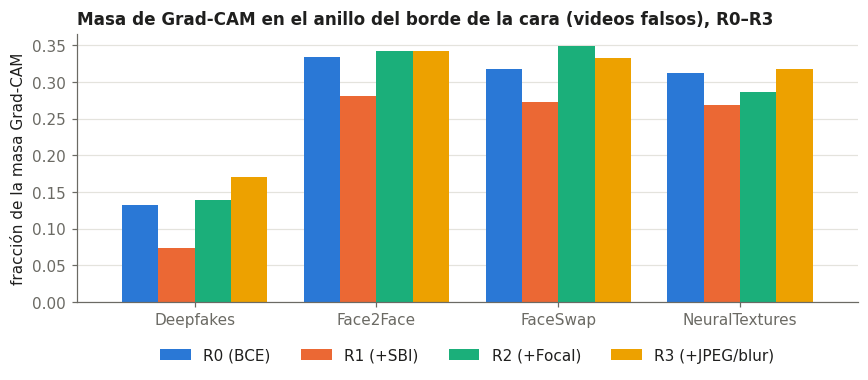

In [8]:
borde = (regiones[regiones.clase == "falso"].groupby(["test", "modelo"], observed=True)["masa_borde"].mean().unstack())
borde = borde.reindex([t for t in A.TEST_ORDER if t in borde.index])
ax = borde.plot.bar(figsize=(8, 3.6), color=S.SERIES[:borde.shape[1]], width=0.8, rot=0)
ax.set_ylabel("fracción de la masa Grad-CAM"); ax.set_xlabel("")
ax.set_title("Masa de Grad-CAM en el anillo del borde de la cara (videos falsos), R0–R3", loc="left"); ax.grid(axis="x", visible=False)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=4)
plt.tight_layout(); plt.savefig(OUT / "fig_gradcam_fase_d_masa_borde.png", dpi=200); plt.show()

## 4. FaceSwap con R3: videos detectados frente a no detectados

In [9]:
fs = regiones[(regiones.test == "FaceSwap") & (regiones.clase == "falso") & (regiones.modelo == "R3 (+JPEG/blur)")]
fs.groupby("acierto")[["masa_interior", "masa_borde", "masa_fuera", "area_50"]].agg(["mean", "count"]).round(3)

masa_interior       masa_borde       masa_fuera       area_50      
                 mean count       mean count       mean count    mean count
acierto                                                                    
False           0.199   209      0.333   209      0.468   209   0.143   209
True            0.614    71      0.332    71      0.054    71   0.084    71

## 5. Contraste con la predicción 4 de H-D1
Resultados de la v2 (24/11/2026), 2 frames por video de test (140 videos falsos por manipulación), regiones concéntricas aproximadas. Registrado como C-02 en `docs/DECISIONS.md`.

| Predicción | Resultado | ¿Se cumplió? |
|---|---|---|
| Con R1, la masa de borde sube en los falsos frente a R0 (IC 95 % del Δ por encima de 0) | Δ R1 − R0: Deepfakes −0.059 [−0.070, −0.049], Face2Face −0.054, FaceSwap −0.045, NeuralTextures −0.044; los cuatro IC excluyen 0 | **No** (baja) |

**Lectura.** Los SBI mejoran el AUC en FaceSwap y Face2Face (notebook 07), pero el modelo no pasa a mirar el contorno de la cara: con R1 la masa del borde baja y se va fuera de la cara; con R3 el borde no cambia (FaceSwap +0.014 [−0.000, 0.030]) y la masa pasa al **interior** (FaceSwap +0.240, Face2Face +0.287, NeuralTextures +0.193; `gradcam_fase_d_delta_vs_r0.csv`). Ese cambio acompaña a la fracción de falsos detectados con umbral 0.5 (FaceSwap: 0.4 % con R0, 25 % con R3). Grad-CAM sigue la decisión: los falsos detectados tienen la masa en el interior y los no detectados, fuera, como en el 06. Una lectura compatible, no medida: los SBI enseñan diferencias de color y textura dentro de la región mezclada, no su borde.

Límites (los mismos del 06): regiones concéntricas aproximadas, una sola semilla y Grad-CAM muestra correlación, no causalidad.

Para llevar los resultados al repo: descargar `resultados/` del output (`gradcam_fase_d_*.csv`, `fig_gradcam_fase_d_masa_borde.png`) a `results/metrics/fase_d/`. La carpeta `privado/` no se descarga.